# iaCarne — Sprint 4: EDA avançada e atributos temporais

Este caderno analisa **dados sintéticos** para preparar a previsão de **venda observada**, não de demanda verdadeira. O objetivo é conferir a matriz e explorar calendário, lags e médias móveis. Nenhum modelo, baseline ou divisão treino/teste é criado.

Para o dia D, os atributos históricos usam apenas valores até D−1. As relações abaixo são descritivas: não demonstram causalidade ou ganho operacional.

## 1. Importações e configuração
Usamos pandas para tabelas e matplotlib para os gráficos. Os arquivos são salvos apenas em `reports/sprint4/`. O diretório de trabalho pode ser a raiz ou a pasta de notebooks.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data/modeling/iacarne_modelagem.csv").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/modeling/iacarne_modelagem.csv").exists(), "Execute na raiz ou em notebooks/"
REPORTS = ROOT / "reports/sprint4"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
TARGET = "quantidade_vendida_kg"
FEATURES = [
    "produto_id", "corte", "categoria_anatomica", "perfil_uso",
    "dia_semana", "fim_de_semana", "mes", "semana_ano",
    "venda_lag_1", "venda_lag_7", "venda_lag_14", "venda_lag_28",
    "venda_media_7", "venda_media_14", "venda_media_28",
]
LAGS = ["venda_lag_1", "venda_lag_7", "venda_lag_14", "venda_lag_28"]
MOVING = ["venda_media_7", "venda_media_14", "venda_media_28"]
HISTORY = LAGS + MOVING
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11, "axes.grid": True,
                     "grid.alpha": 0.2, "axes.spines.top": False, "axes.spines.right": False})
figures = []
def save_figure(fig, name):
    fig.text(0.99, 0.005, "Dados sintéticos — venda observada", ha="right", fontsize=9)
    fig.tight_layout(rect=(0, 0.035, 1, 1))
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight")
    figures.append(name)
    plt.show()
    plt.close(fig)
def br(value, digits=2):
    return f"{value:,.{digits}f}".replace(",", "X").replace(".", ",").replace("X", ".")

## 2. Carregamento e conferência da origem
A matriz de modelagem é a fonte das análises de atributos. A base tratada será usada apenas para ruptura, promoção e preço. Os JSONs servem para verificar os hashes, sem acrescentar observações. Nenhum dado externo ou arquivo de auditoria é carregado.

In [2]:
model_path = ROOT / "data/modeling/iacarne_modelagem.csv"
oper_path = ROOT / "data/processed/iacarne_vendas_tratado.csv"
meta = json.loads((ROOT / "data/modeling/relatorio_modelagem.json").read_text(encoding="utf-8"))
etl_meta = json.loads((ROOT / "data/processed/relatorio_pipeline.json").read_text(encoding="utf-8"))
assert hashlib.sha256(model_path.read_bytes()).hexdigest() == meta["hash_sha256_modelagem"]
assert hashlib.sha256(oper_path.read_bytes()).hexdigest() == meta["hash_sha256_fonte"] == etl_meta["sha256_saida"]
model = pd.read_csv(model_path, parse_dates=["data"], keep_default_na=False)
oper = pd.read_csv(oper_path, parse_dates=["data"], keep_default_na=False)
assert meta["natureza_dados"] == "sinteticos"
display(pd.DataFrame([
    {"arquivo": str(model_path.relative_to(ROOT)), "linhas": len(model), "colunas": model.shape[1], "uso": "atributos e alvo"},
    {"arquivo": str(oper_path.relative_to(ROOT)), "linhas": len(oper), "colunas": oper.shape[1], "uso": "contexto operacional"},
]))
print("Hashes conferidos. Dados sintéticos; sem dados reais autorizados.")

,arquivo,linhas,colunas,uso
0,data\modeling\iacarne_modelagem.csv,7077,17,atributos e alvo
1,data\processed\iacarne_vendas_tratado.csv,7665,28,contexto operacional


Hashes conferidos. Dados sintéticos; sem dados reais autorizados.


## 3. Dimensões, tipos e qualidade
Conferimos chaves, valores ausentes, cobertura diária e a lista exata das 15 features. A data é referência temporal e a quantidade vendida é o alvo. A remoção inicial corresponde ao aquecimento de 28 dias por produto.

In [3]:
assert list(model.columns) == ["data", TARGET, *FEATURES]
assert model.shape == (7077, 17)
assert model.produto_id.nunique() == 21
assert not model.isna().any().any()
assert not model.duplicated(["produto_id", "data"]).any()
assert model.groupby("produto_id").size().eq(337).all()
assert model.equals(model.sort_values(["produto_id", "data"]).reset_index(drop=True))
assert model.groupby("produto_id").data.diff().dropna().eq(pd.Timedelta(days=1)).all()
assert model[TARGET].ge(0).all()
assert model[HISTORY].ge(0).all().all()
display(pd.DataFrame({"tipo": model.dtypes.astype(str), "nulos": model.isna().sum()}))
print(f"Modelagem: {len(model)} linhas, {model.produto_id.nunique()} produtos, {model.data.nunique()} dias.")
print(f"Período: {model.data.min():%d/%m/%Y} a {model.data.max():%d/%m/%Y}.")
print(f"Base tratada: {oper.data.min():%d/%m/%Y} a {oper.data.max():%d/%m/%Y}; diferença: {len(oper)-len(model)} linhas.")

,tipo,nulos
data,datetime64[ns],0
quantidade_vendida_kg,float64,0
produto_id,object,0
corte,object,0
categoria_anatomica,object,0
perfil_uso,object,0
dia_semana,object,0
fim_de_semana,int64,0
mes,int64,0
semana_ano,int64,0


Modelagem: 7077 linhas, 21 produtos, 337 dias.
Período: 29/09/2025 a 31/08/2026.
Base tratada: 01/09/2025 a 31/08/2026; diferença: 588 linhas.


## 4. Distribuição da venda observada
Cada observação corresponde a um produto em um dia. O histograma reúne cortes com níveis de venda diferentes; por isso também faremos comparações por corte.

,kg por produto/dia
count,7077.000000
mean,14.953973
std,6.583483
min,4.320000
5%,7.168000
25%,10.260000
50%,13.350000
75%,18.170000
95%,28.384000
max,50.160000


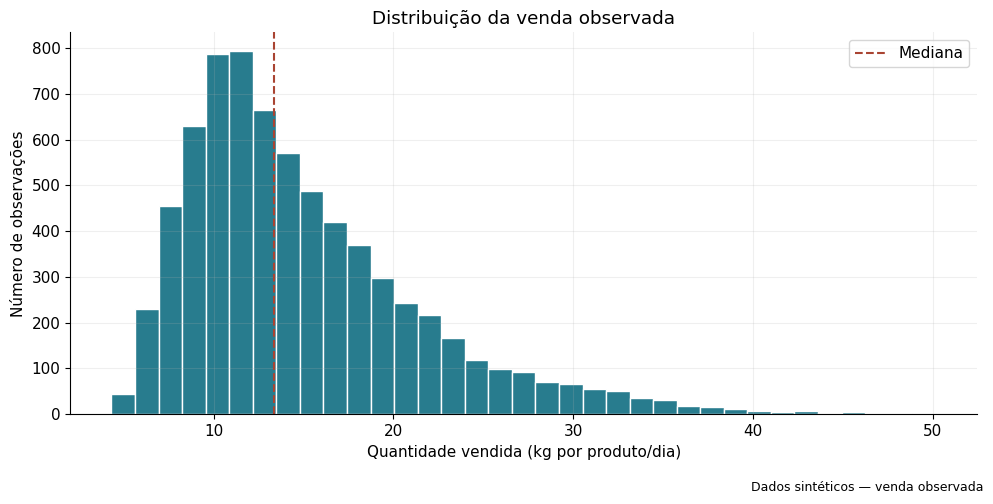

In [4]:
target_stats = model[TARGET].describe(percentiles=[.05, .25, .5, .75, .95])
display(target_stats.rename("kg por produto/dia").to_frame())
fig, ax = plt.subplots()
ax.hist(model[TARGET], bins=35, color="#287c8e", edgecolor="white")
ax.axvline(model[TARGET].median(), color="#a94432", linestyle="--", label="Mediana")
ax.set(title="Distribuição da venda observada", xlabel="Quantidade vendida (kg por produto/dia)", ylabel="Número de observações")
ax.legend()
save_figure(fig, "01_distribuicao_vendas.png")

## 5. Venda média e mediana por corte
Comparamos kg por dia de cada corte, sem confundir média diária com volume acumulado. Todos têm 337 observações no período de modelagem.

,media,mediana,observacoes
corte,,,
Acém,28.55,27.33,337
Patinho,23.69,22.37,337
Coxão Mole,21.65,20.48,337
Costelão,21.02,19.57,337
Alcatra,20.93,19.69,337
Paleta,17.30,16.39,337
Coxão Duro,15.07,14.41,337
Fraldinha,15.07,14.10,337
Músculo Dianteiro,13.94,13.19,337


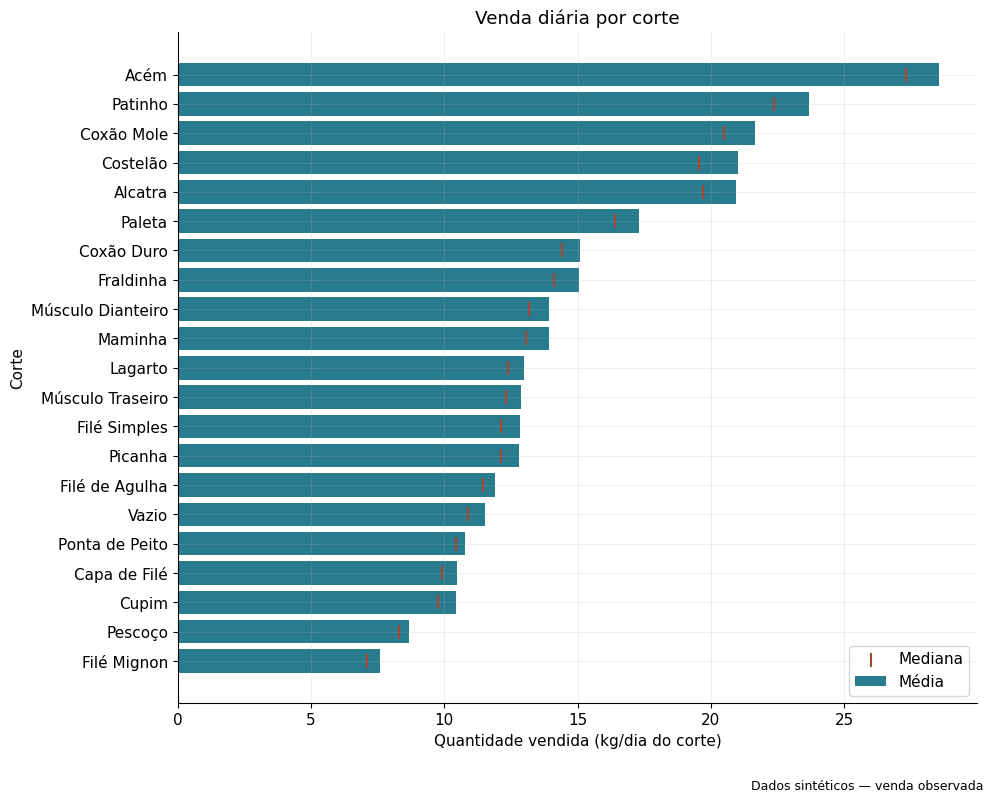

In [5]:
by_cut = model.groupby("corte")[TARGET].agg(media="mean", mediana="median", observacoes="size").sort_values("media")
display(by_cut.sort_values("media", ascending=False).round(2))
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(by_cut.index, by_cut.media, color="#287c8e", label="Média")
ax.scatter(by_cut.mediana, by_cut.index, color="#a94432", marker="|", s=90, label="Mediana", zorder=3)
ax.set(title="Venda diária por corte", xlabel="Quantidade vendida (kg/dia do corte)", ylabel="Corte")
ax.legend()
save_figure(fig, "02_media_por_corte.png")

## 6. Evolução temporal agregada
Somamos os 21 cortes em cada dia. A linha suavizada é uma média descritiva dos totais dos últimos sete dias, incluindo o dia mostrado: ela não é uma feature da matriz.

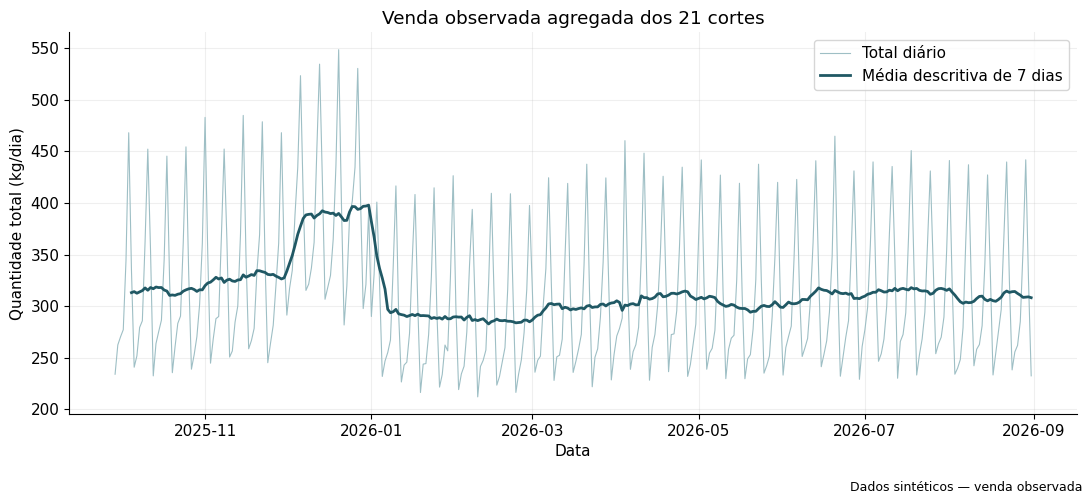

Média diária agregada: 314,03 kg; mínimo: 212,23 kg; máximo: 548,28 kg.


In [6]:
daily = model.groupby("data")[TARGET].sum().sort_index()
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(daily.index, daily, color="#9ebfc5", linewidth=.8, label="Total diário")
ax.plot(daily.index, daily.rolling(7, min_periods=7).mean(), color="#205864", linewidth=2, label="Média descritiva de 7 dias")
ax.set(title="Venda observada agregada dos 21 cortes", xlabel="Data", ylabel="Quantidade total (kg/dia)")
ax.legend()
save_figure(fig, "03_evolucao_temporal.png")
print(f"Média diária agregada: {br(daily.mean())} kg; mínimo: {br(daily.min())} kg; máximo: {br(daily.max())} kg.")

## 7. Padrão por dia da semana
A média é calculada por observação produto/dia. Apresentamos também as quantidades de observações para mostrar a cobertura de cada dia da semana.

,media,mediana,observacoes
dia_semana,,,
segunda,11.46,10.26,1029
terca,12.37,11.14,1008
quarta,13.06,11.74,1008
quinta,13.98,12.53,1008
sexta,16.89,15.12,1008
sabado,21.15,18.92,1008
domingo,15.83,14.21,1008


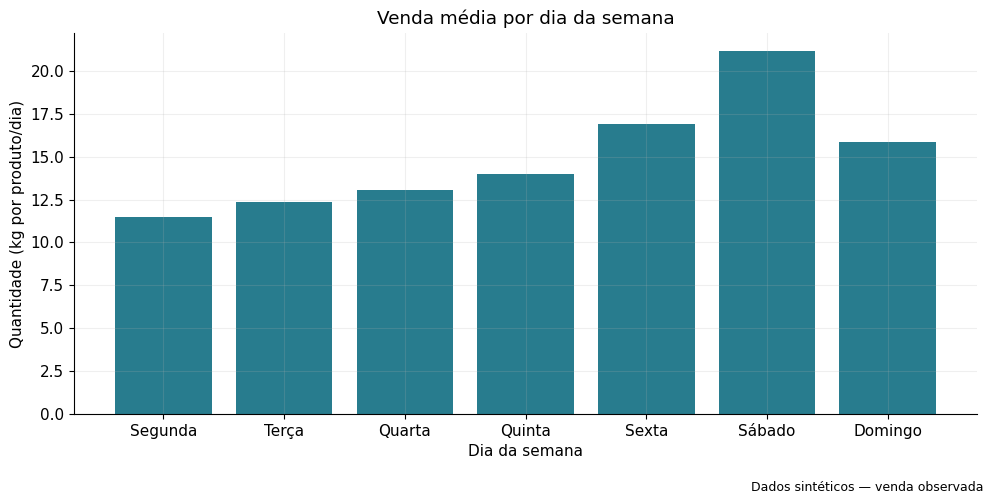

In [7]:
week_order = ["segunda", "terca", "quarta", "quinta", "sexta", "sabado", "domingo"]
week_labels = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]
weekday = model.groupby("dia_semana")[TARGET].agg(media="mean", mediana="median", observacoes="size").reindex(week_order)
display(weekday.round(2))
fig, ax = plt.subplots()
ax.bar(week_labels, weekday.media, color="#287c8e")
ax.set(title="Venda média por dia da semana", xlabel="Dia da semana", ylabel="Quantidade (kg por produto/dia)")
save_figure(fig, "04_media_dia_semana.png")

## 8. Padrão mensal
Usamos ano/mês em ordem cronológica e médias, sem comparar totais de meses com durações diferentes. Setembro/2025 tem somente dois dias após o aquecimento. Há apenas um ano sintético: não podemos demonstrar repetição anual de sazonalidade.

,media,mediana,dias,observacoes
mes_periodo,,,,
2025-09,11.83,10.80,2,42
2025-10,14.96,13.06,31,651
2025-11,15.91,14.13,30,630
2025-12,18.31,16.29,31,651
2026-01,14.11,12.57,31,651
2026-02,13.59,12.32,28,588
2026-03,14.15,12.53,31,651
2026-04,14.56,12.92,30,630
2026-05,14.61,13.00,31,651


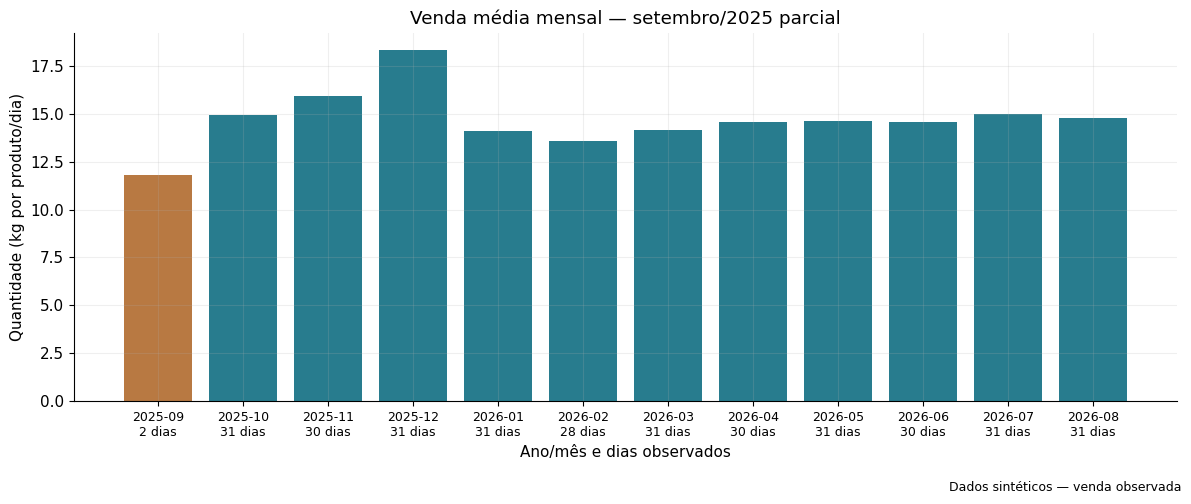

In [8]:
monthly = model.assign(mes_periodo=model.data.dt.to_period("M")).groupby("mes_periodo").agg(
    media=(TARGET, "mean"), mediana=(TARGET, "median"), dias=("data", "nunique"), observacoes=(TARGET, "size"))
display(monthly.round(2))
labels = [f"{period}\n{int(days)} dias" for period, days in zip(monthly.index, monthly.dias)]
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(labels, monthly.media, color=["#b87942" if d < 28 else "#287c8e" for d in monthly.dias])
ax.set(title="Venda média mensal — setembro/2025 parcial", xlabel="Ano/mês e dias observados", ylabel="Quantidade (kg por produto/dia)")
ax.tick_params(axis="x", labelsize=9)
save_figure(fig, "05_media_mensal.png")

## 9. Relação entre alvo e defasagens
Os lags usam a venda do mesmo produto em D−1, D−7, D−14 e D−28. Comparamos a correlação de Pearson global com a correlação após subtrair a média de cada produto. Esta segunda medida ajuda a separar diferenças de nível entre cortes; é apenas descritiva e não será usada como transformação de treinamento.

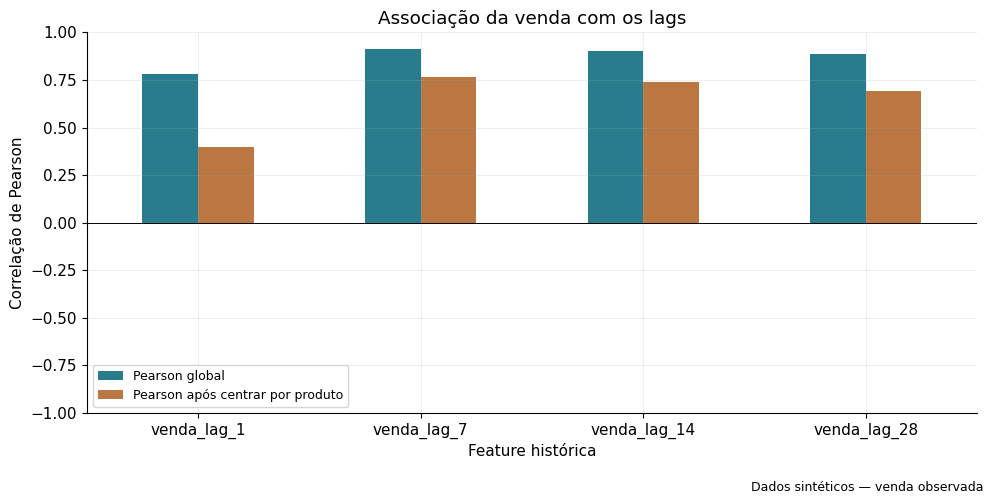

,Pearson global,Pearson após centrar por produto
venda_lag_1,0.7795,0.3985
venda_lag_7,0.9148,0.7680
venda_lag_14,0.9036,0.7378
venda_lag_28,0.8859,0.6902


In [9]:
centered = model[[TARGET, *HISTORY]] - model.groupby("produto_id")[[TARGET, *HISTORY]].transform("mean")
associations = pd.DataFrame({
    "Pearson global": model[[TARGET, *HISTORY]].corr()[TARGET].reindex(HISTORY),
    "Pearson após centrar por produto": centered.corr()[TARGET].reindex(HISTORY),
})
fig, ax = plt.subplots()
associations.loc[LAGS].plot.bar(ax=ax, color=["#287c8e", "#ba7741"], rot=0)
ax.axhline(0, color="black", linewidth=.7)
ax.set(title="Associação da venda com os lags", xlabel="Feature histórica", ylabel="Correlação de Pearson", ylim=(-1, 1))
ax.legend(fontsize=9)
save_figure(fig, "06_associacao_lags.png")
display(associations.loc[LAGS].round(4))

## 10. Relação entre alvo e médias móveis
As médias das features usam `shift(1)` antes da janela completa de 7, 14 ou 28 dias. Não incluem a venda do próprio dia. A comparação global e por produto evita atribuir toda a associação à dinâmica temporal.

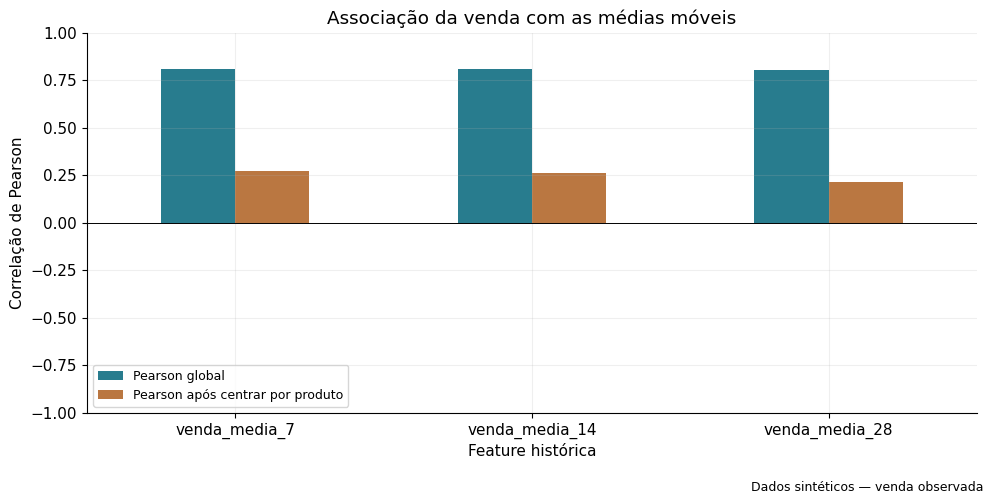

,Pearson global,Pearson após centrar por produto
venda_media_7,0.8107,0.2738
venda_media_14,0.8102,0.2633
venda_media_28,0.8046,0.2153


In [10]:
fig, ax = plt.subplots()
associations.loc[MOVING].plot.bar(ax=ax, color=["#287c8e", "#ba7741"], rot=0)
ax.axhline(0, color="black", linewidth=.7)
ax.set(title="Associação da venda com as médias móveis", xlabel="Feature histórica", ylabel="Correlação de Pearson", ylim=(-1, 1))
ax.legend(fontsize=9)
save_figure(fig, "07_associacao_medias_moveis.png")
display(associations.loc[MOVING].round(4))

## 11. Resumo dos tipos de histórico
Comparamos todas as features históricas em uma tabela. Conferimos também os valores contra a base tratada, usando somente o passado de cada produto. Essa conferência inclui os 28 dias anteriores ao início da matriz, necessários para calcular as primeiras linhas válidas.

In [11]:
history_source = oper.sort_values(["produto_id", "data"]).copy()
grouped = history_source.groupby("produto_id", sort=False)[TARGET]
for lag in (1, 7, 14, 28):
    history_source[f"venda_lag_{lag}"] = grouped.shift(lag)
for window in (7, 14, 28):
    history_source[f"venda_media_{window}"] = grouped.transform(lambda values: values.shift(1).rolling(window, min_periods=window).mean())
check = model.merge(history_source[["produto_id", "data", *HISTORY]], on=["produto_id", "data"], validate="one_to_one", suffixes=("", "_conferido"))
for feature in HISTORY:
    assert (check[feature] - check[f"{feature}_conferido"]).abs().le(1e-10).all(), feature
summary = associations.copy()
summary.insert(0, "tipo", ["Lag" if f in LAGS else "Média móvel" for f in HISTORY])
display(summary.round(4))
print("Lags e médias conferidos: diferenças máximas dentro de 1e-10 kg.")

,tipo,Pearson global,Pearson após centrar por produto
venda_lag_1,Lag,0.7795,0.3985
venda_lag_7,Lag,0.9148,0.7680
venda_lag_14,Lag,0.9036,0.7378
venda_lag_28,Lag,0.8859,0.6902
venda_media_7,Média móvel,0.8107,0.2738
venda_media_14,Média móvel,0.8102,0.2633
venda_media_28,Média móvel,0.8046,0.2153


Lags e médias conferidos: diferenças máximas dentro de 1e-10 kg.


## 12. Ruptura e interpretação da venda observada
Usamos a base tratada completa (365 dias), separada da matriz de modelagem. Comparamos contagem, média e mediana com e sem ruptura. A composição dos grupos pode diferir por produto e data. Uma venda em ruptura pode ser censurada pelo estoque: não conhecemos a quantidade que teria sido vendida com disponibilidade suficiente. Ruptura de D continua excluída das features de D.

,observacoes,media,mediana
ruptura_estoque,,,
Sem ruptura,6423,14.47,12.84
Com ruptura,1242,17.16,15.46


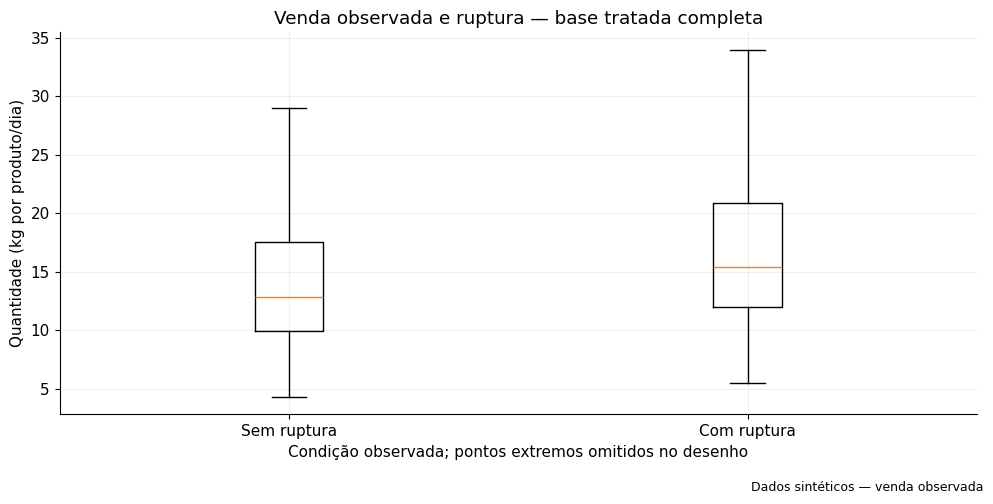

Ruptura: 1242 de 7665 observações (16,20%).


In [12]:
rupture = oper.groupby("ruptura_estoque")[TARGET].agg(observacoes="size", media="mean", mediana="median")
rupture.index = rupture.index.map({0: "Sem ruptura", 1: "Com ruptura"})
display(rupture.round(2))
fig, ax = plt.subplots()
values = [oper.loc[oper.ruptura_estoque.eq(flag), TARGET] for flag in (0, 1)]
ax.boxplot(values, tick_labels=["Sem ruptura", "Com ruptura"], showfliers=False)
ax.set(title="Venda observada e ruptura — base tratada completa", xlabel="Condição observada; pontos extremos omitidos no desenho", ylabel="Quantidade (kg por produto/dia)")
save_figure(fig, "08_ruptura_venda_observada.png")
print(f"Ruptura: {int(oper.ruptura_estoque.sum())} de {len(oper)} observações ({br(100 * oper.ruptura_estoque.mean())}%).")

## 13. Promoção e preço como contexto
Esta tabela usa a base tratada completa. Os grupos podem ter produtos, datas e preços diferentes. Portanto, a diferença de médias não mede o efeito causal da promoção. Preço e promoção não entram na matriz inicial porque sua disponibilidade antes da previsão não foi comprovada.

In [13]:
promotion = oper.groupby("promocao").agg(observacoes=(TARGET, "size"), venda_media=(TARGET, "mean"), preco_medio=("preco_venda_kg", "mean"))
promotion.index = promotion.index.map({0: "Sem promoção", 1: "Com promoção"})
display(promotion.round(2))
print("Médias agrupadas; não estimam efeito da promoção nem elasticidade de preço.")

,observacoes,venda_media,preco_medio
promocao,,,
Sem promoção,7130,14.77,48.26
Com promoção,535,16.73,41.84


Médias agrupadas; não estimam efeito da promoção nem elasticidade de preço.


## 14. Correlação das variáveis numéricas relevantes
A matriz reúne o alvo e as sete features históricas. Não inclui receita, custos, margem, saldo final ou identificadores. Mês e semana ISO não são tratados como escalas lineares neste gráfico. Correlação alta entre históricos pode indicar redundância; não prova capacidade preditiva.

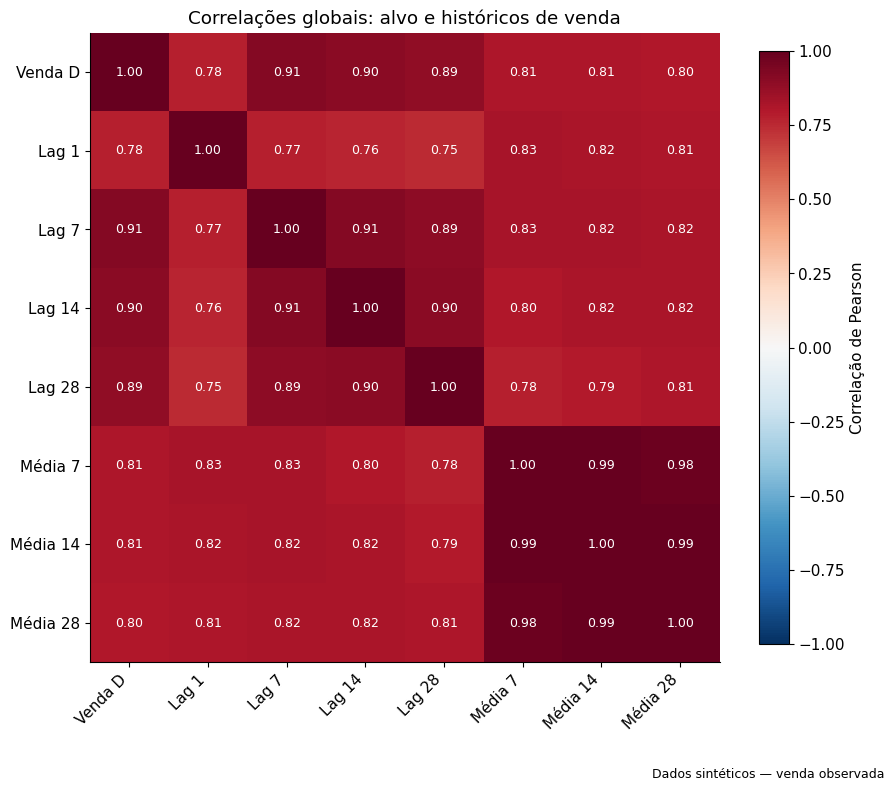

In [14]:
numeric = [TARGET, *HISTORY]
correlation = model[numeric].corr()
labels = ["Venda D", "Lag 1", "Lag 7", "Lag 14", "Lag 28", "Média 7", "Média 14", "Média 28"]
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels=labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels=labels)
ax.set_title("Correlações globais: alvo e históricos de venda")
ax.grid(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = correlation.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if abs(value) > .6 else "black", fontsize=9)
fig.colorbar(image, ax=ax, label="Correlação de Pearson", shrink=.85)
save_figure(fig, "09_correlacao_historicos.png")

## 15. Seleção para o primeiro experimento da Sprint 5
Mantemos exatamente as 15 features aprovadas. Identificadores e descrições categóricas ainda precisarão de codificação no pipeline de ML. `produto_id` e `corte` representam a mesma identidade; essa redundância deverá ser avaliada depois, sem alterar a matriz nesta etapa. Data é referência e quantidade vendida é alvo.

A análise exploratória usa o período inteiro. Seus resultados não podem ser apresentados como desempenho em dados de teste. A Sprint 5 deverá definir uma avaliação temporal e ajustar qualquer transformação aprendida somente nos dados de treino.

In [15]:
display(pd.DataFrame({"feature": FEATURES}))
print("Referência: data | Alvo: quantidade_vendida_kg")
print("Nenhuma seleção automática, codificação, normalização, divisão ou treinamento foi executado.")

,feature
0,produto_id
1,corte
2,categoria_anatomica
3,perfil_uso
4,dia_semana
5,fim_de_semana
6,mes
7,semana_ano
8,venda_lag_1
9,venda_lag_7


Referência: data | Alvo: quantidade_vendida_kg
Nenhuma seleção automática, codificação, normalização, divisão ou treinamento foi executado.


## 16. Limitações
- Dados sintéticos; não são vendas de um estabelecimento real.
- Apenas um ciclo anual; setembro/2025 tem dois dias na matriz após o aquecimento.
- Os padrões podem refletir regras da simulação.
- Venda observada não é demanda verdadeira; ruptura pode censurar a venda.
- Comparações de grupos e correlações não demonstram causalidade.
- Dados reais dependem de autorização; não há coleta ou autorização comprovada.
- Não foram comprovados ganhos comerciais ou redução de desperdício.
- Nenhum modelo foi treinado. Associação exploratória não equivale a desempenho preditivo.

## 17. Conclusão e síntese reproduzível
O bloco final registra os valores calculados neste caderno no relatório de insights. A conclusão diferencia padrões globais de diferenças entre produtos. Na Sprint 5, a avaliação deverá respeitar a ordem temporal e o horizonte de um dia: valores observados só podem atualizar o histórico depois de disponíveis.

In [16]:
best_lag = associations.loc[LAGS, "Pearson após centrar por produto"].idxmax()
best_moving = associations.loc[MOVING, "Pearson após centrar por produto"].idxmax()
full_months = monthly.loc[monthly.dias.ge(28)]
best_month = full_months.media.idxmax()
worst_month = full_months.media.idxmin()
weekday_names = dict(zip(week_order, week_labels))
strong_day = weekday_names[weekday.media.idxmax()]
weak_day = weekday_names[weekday.media.idxmin()]
feature_lines = "\n".join(f"- `{feature}`" for feature in FEATURES)
association_lines = "\n".join(
    f"| {feature} | {br(row.iloc[0], 4)} | {br(row.iloc[1], 4)} |"
    for feature, row in associations.iterrows()
)
text = f"""# Sprint 4 — Insights da EDA avançada

## Objetivo e bases
Analisar atributos para prever venda observada por produto no dia seguinte, sem treinar modelos.
Os dados são sintéticos. A matriz `data/modeling/iacarne_modelagem.csv` tem {br(len(model), 0)} registros,
21 produtos e 337 dias por produto, de {model.data.min():%d/%m/%Y} a {model.data.max():%d/%m/%Y}.
São 17 colunas, zero nulos e zero duplicatas produto/data. Os hashes foram conferidos contra os relatórios.
A base tratada tem {br(len(oper), 0)} registros, de {oper.data.min():%d/%m/%Y} a {oper.data.max():%d/%m/%Y},
e foi usada para o contexto operacional e a conferência das defasagens. Não foi usado ground truth.

## Distribuição e cortes
A venda média é {br(model[TARGET].mean())} kg por produto/dia; a mediana é {br(model[TARGET].median())} kg.
O percentil 95 é {br(model[TARGET].quantile(.95))} kg.
{by_cut.media.idxmax()} apresenta a maior média diária ({br(by_cut.media.max())} kg),
e {by_cut.media.idxmin()} a menor ({br(by_cut.media.min())} kg).
São médias diárias, não volumes acumulados. A média do total diário dos 21 cortes é {br(daily.mean())} kg.

## Comportamento temporal
{strong_day} tem a maior média por produto/dia ({br(weekday.media.max())} kg)
e {weak_day} a menor ({br(weekday.media.min())} kg).
Entre os meses com pelo menos 28 dias observados, {best_month} tem a maior média
({br(full_months.media.max())} kg por produto/dia) e {worst_month} a menor ({br(full_months.media.min())} kg).
Setembro/2025 tem somente dois dias após o aquecimento; sua média não representa o mês completo.
A base contém apenas um ano sintético, sem evidência de repetição anual em dados reais.

## Lags e médias móveis
Os históricos foram conferidos contra a base tratada: apenas valores até D-1, por produto.
As médias usam janela completa de 7, 14 ou 28 dias após shift(1).

| Feature | Pearson global com alvo | Pearson após centrar por produto |
|---|---:|---:|
{association_lines}

A centralização subtrai a média de cada produto somente para esta análise descritiva.
Ela não é uma transformação de treino e não altera o dataset.
O maior coeficiente após centralização entre os lags é de `{best_lag}`
({br(associations.loc[best_lag].iloc[1], 4)}); entre as médias, de `{best_moving}`
({br(associations.loc[best_moving].iloc[1], 4)}).
Esses atributos são candidatos a testar, não vencedores comprovados.
A diferença entre os coeficientes globais e centrados mostra a influência dos níveis de venda dos produtos.
Os históricos também podem ser redundantes entre si; a correlação não substitui validação temporal.

## Ruptura e promoção
Na base tratada completa, há {int(oper.ruptura_estoque.sum())} observações com ruptura em {len(oper)}
({br(100 * oper.ruptura_estoque.mean())}%). A venda média é {br(rupture.loc['Com ruptura', 'media'])} kg
com ruptura e {br(rupture.loc['Sem ruptura', 'media'])} kg sem ruptura.
Esses grupos têm composições distintas. Não se infere efeito causal: em ruptura,
a venda pode ser censurada pela disponibilidade e não revela a demanda não atendida.
Ruptura de D não entra nas features de D.

Com promoção, a média observada é {br(promotion.loc['Com promoção', 'venda_media'])} kg;
sem promoção, {br(promotion.loc['Sem promoção', 'venda_media'])} kg.
Os preços médios agrupados são R$ {br(promotion.loc['Com promoção', 'preco_medio'])}/kg e
R$ {br(promotion.loc['Sem promoção', 'preco_medio'])}/kg, respectivamente.
Não são comparações controladas por corte/data e não medem causalidade ou elasticidade.
Preço, promoção e desconto permanecem excluídos: disponibilidade antecipada não comprovada.

## Features para a Sprint 5
{feature_lines}

`data` é referência temporal e `{TARGET}` é o alvo, nunca feature contemporânea.
As categorias ainda precisam de codificação no pipeline de ML. Produto e nome do corte são redundantes;
a manutenção de ambos segue o contrato inicial e poderá ser avaliada em experimentos posteriores.
Receita, custo total, margem, perdas, saldo final e ruptura do próprio dia permanecem fora da matriz.

## Limitações e próximos cuidados
Dados sintéticos, apenas um ano e padrões influenciados pelas premissas da simulação.
Não há dados reais autorizados, inferência causal, ganho operacional ou redução de desperdício comprovados.
Nenhum modelo, baseline ou divisão treino/teste foi criado nesta etapa.
A EDA explorou todo o período; não constitui avaliação independente de um modelo.
Na Sprint 5, definir avaliação temporal, manter datas futuras fora do treino e ajustar codificações
somente no treino. Em avaliação diária, atualizar históricos apenas quando a venda anterior estiver disponível;
prever vários dias de uma vez exigiria outro protocolo. Não usar resultados de D para prever D.

Foram produzidos {len(figures)} gráficos em `reports/sprint4/figures/`.
"""
(REPORTS / "insights.md").write_text(text, encoding="utf-8")
print(text)
assert len(figures) == 9
assert all((FIGURES / name).is_file() for name in figures)

# Sprint 4 — Insights da EDA avançada

## Objetivo e bases
Analisar atributos para prever venda observada por produto no dia seguinte, sem treinar modelos.
Os dados são sintéticos. A matriz `data/modeling/iacarne_modelagem.csv` tem 7.077 registros,
21 produtos e 337 dias por produto, de 29/09/2025 a 31/08/2026.
São 17 colunas, zero nulos e zero duplicatas produto/data. Os hashes foram conferidos contra os relatórios.
A base tratada tem 7.665 registros, de 01/09/2025 a 31/08/2026,
e foi usada para o contexto operacional e a conferência das defasagens. Não foi usado ground truth.

## Distribuição e cortes
A venda média é 14,95 kg por produto/dia; a mediana é 13,35 kg.
O percentil 95 é 28,38 kg.
Acém apresenta a maior média diária (28,55 kg),
e Filé Mignon a menor (7,59 kg).
São médias diárias, não volumes acumulados. A média do total diário dos 21 cortes é 314,03 kg.

## Comportamento temporal
Sábado tem a maior média por produto/dia (21,15 kg)
e Segunda a menor (11,46 kg).
Entre os mese